# Reto 2 · Feature engineering

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: decidir **qué información describe de verdad a un cliente** y prepararla para K-Means.
Todo el proceso está encapsulado en un `Pipeline` de scikit-learn definido en
[`features.py`](features.py), que reutilizan los notebooks de los retos 3 y 4.

**Decisiones de partida (vienen del Reto 1):**
1. **Una fila por cliente.** El dataset original tiene una fila por relación cliente–vehículo.
2. **El país no segmenta.** Suiza y Austria tienen niveles de renta muy distintos; si el modelo ve el
   país o el poder adquisitivo absoluto, los clusters separan *países* en lugar de *tipos de cliente*.
   Por eso `country_code` queda fuera del modelo y el poder adquisitivo se expresa **relativo a su país**.
3. **La telemetría no se imputa** (falta en ~60 %): entra solo como indicador de *vehículo conectado*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config

from features import (cargar_datos, construir_pipeline, agregar_clientes, FEATURES,
                      CAT_ORDINALES, NUM_LOG, NUM, TOPES, GAMA_POR_CLASE,
                      ORDEN_EDAD, ORDEN_FINANCIACION)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.2f}".format)
set_config(display="text")

df = cargar_datos()
df.shape

(302850, 39)

## 1. El pipeline

| Paso | Qué hace |
|---|---|
| `agregar` | Agrega las relaciones cliente–vehículo a **1 fila por cliente** y crea las features derivadas |
| `recortar` | Pone **topes superiores** a variables con colas extremas (flotas, coches clásicos) |
| `preprocesar` | `ColumnTransformer`: imputación, codificación ordinal, `log1p` y escalado estándar |

In [2]:
pipe = construir_pipeline()
pipe

Pipeline(steps=[('agregar',
                 FunctionTransformer(func=<function agregar_clientes at 0x00000201B8FB16F0>)),
                ('recortar',
                 FunctionTransformer(func=<function recortar_extremos at 0x00000201B9081170>)),
                ('preprocesar',
                 ColumnTransformer(transformers=[('ord',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificar',
                                                                   OrdinalEncoder(categories=[...
                                                  ['n_vehiculos_historico',
                                                   'n_vehiculos_actuales']),
                                                 ('num',
                                                  Pipeline(steps=[('imputar',
          

In [3]:
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
print("Matriz para K-Means:", X.shape, "· nulos:", int(X.isna().sum().sum()))
X.head()

Matriz para K-Means: (173456, 13) · nulos: 0


,age_range,finance_leasing_status,n_vehiculos_historico,n_vehiculos_actuales,meses_cliente,antiguedad_vehiculo,gama_max,pct_electrificado,pct_furgoneta,n_canales_consentidos,tiene_telemetria,poder_adquisitivo_pct_pais,visitas_taller_pct_pais
client_id,,,,,,,,,,,,,
000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,-0.64,-0.62,0.80,0.11,0.10,-0.52,0.01,-0.52,-0.36,-2.55,0.82,-1.01,1.07
0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fabd499647aba8e3a8d8a,-1.31,-0.62,-0.50,0.11,0.73,-0.13,1.15,-0.52,-0.36,-1.05,0.82,-1.74,-1.42
00046586c51084441db2d37ad19472cda98a6552323fab6179494687beae03db,1.36,-0.62,0.80,0.11,0.78,-0.78,0.01,-0.52,3.06,0.46,0.82,1.01,1.49
0005e6cc04ecf053522bdce2336695e8a28b3205f6ee769cd0585f6e6d084894,-0.64,-0.62,4.98,-2.44,0.34,-1.30,1.15,0.46,-0.36,0.46,0.82,-0.88,-0.06
000bf66503a67984e23d4cb93ee6751c1c32522917892187ff046e13f0b0d959,0.03,-0.62,-0.50,0.11,0.29,-0.45,1.15,-0.52,-0.36,0.46,0.82,0.99,-0.69


## 2. Features seleccionadas

| Feature | Origen | Tratamiento | Por qué sirve para segmentar |
|---|---|---|---|
| `age_range` | Cliente | Ordinal (6 tramos) + escalado | Etapa vital: condiciona el tipo de vehículo, el canal y la oferta |
| `finance_leasing_status` | Cliente | Ordinal: nunca → antes → leasing → leasing + contado | Relación financiera con la marca: palanca directa para ofertas de renovación |
| `n_vehiculos_historico` | **Derivada** | Tope 10 + `log1p` + escalado | Fidelidad acumulada: cuántos Mercedes ha tenido |
| `n_vehiculos_actuales` | Cliente | Tope 5 + `log1p` + escalado | Tamaño de la relación hoy (0 = cliente inactivo, ≥2 = multi-vehículo) |
| `visitas_taller_pct_pais` | **Derivada** | Media de visitas por vehículo → percentil **dentro de su país** | Uso del taller en garantía: base para planes de mantenimiento (relativo al país por diferencias de registro, ver apartado 4) |
| `meses_cliente` | Cliente | Imputar mediana + escalado | Antigüedad de la relación con la marca |
| `antiguedad_vehiculo` | **Derivada** | Años desde la matriculación + tope 20 | Proximidad a la renovación: un coche de 6+ años es candidato a cambio |
| `gama_max` | **Derivada** | Nivel 1-4 de la clase más alta que ha tenido | Posicionamiento premium del cliente |
| `pct_electrificado` | **Derivada** | % de sus vehículos PHEV/BEV | Afinidad con la electrificación: campañas EQ |
| `pct_furgoneta` | **Derivada** | % de sus vehículos que son furgonetas (grupo T) | Uso profesional / familiar grande (Vito, Sprinter, V-Class) |
| `n_canales_consentidos` | **Derivada** | Suma de consentimientos (teléfono, email, postal) | Alcanzabilidad comercial |
| `tiene_telemetria` | **Derivada** | 1 si algún vehículo envía datos | Cliente "conectado" y digital |
| `poder_adquisitivo_pct_pais` | **Derivada** | Percentil del poder adquisitivo por hogar **dentro de su país**; nulo → 0,5 | Capacidad de compra relativa sin que el país domine |

### Variables descartadas para el modelo (se conservan para **perfilar** los clusters)

| Variable | Motivo |
|---|---|
| `country_code` | Haría que los clusters separaran países (ver apartado 4) |
| Poder adquisitivo absoluto, población, nº de hogares, poder total | Absoluto: depende del país. Resto: tamaño de la zona, no del cliente, y muy correlacionadas entre sí |
| `gender_derived` | Es una variable **inferida**, 17 % desconocida, y segmentar campañas por género inferido es poco robusto y delicado. Se usa solo para describir |
| `role_type` (B2B) | Solo el 1,8 % de relaciones; crearía un cluster minúsculo. Las flotas ya se capturan con nº de vehículos |
| Métricas de telemetría | ~60 % nulas; imputarlas inventaría comportamiento. Solo para perfilar |
| Consentimientos por separado | El email lo tiene el 98 %: no discrimina. Se resume en `n_canales_consentidos` |
| `model_class`, `vehicle_type`, `model_series`, `fuel_type`, `engine_concept` | Alta cardinalidad o redundantes: su información se resume en `gama_max`, `pct_electrificado` y `pct_furgoneta` |
| Identificadores (`client_id`, `vehicle_id`, `zipcode`, índice) | No aportan información analítica (Reto 1) |

## 3. Features derivadas: cómo se construyen

- **`antiguedad_vehiculo`**: años entre la matriculación y la fecha de referencia del extracto (la
  matriculación más reciente del dataset). Se toma el vehículo **actual más reciente**; si el cliente
  no tiene ninguno actual, su vehículo más reciente.
- **`gama_max`**: cada `model_class` se asigna a un nivel (1 compacto · 2 medio · 3 alto · 4 lujo/deportivo).
  Para los `model_class` nulos (modelos nuevos) se usa el prefijo de `vehicle_type` (GLC → 2, GLB → 1…).
- **`pct_electrificado`**: `engine_concept` ∈ {PLUGIN_HYBRID, ELECTRIC}. Cuando `engine_concept` es nulo
  (44 %), se deduce del nombre comercial: `EQ…`, sufijos `e` / `de`, o `electric`.
- **`n_vehiculos_historico`**, **`pct_furgoneta`**, **`tiene_telemetria`**: agregados por cliente de las filas
  de sus vehículos.
- **`visitas_taller_pct_pais`**: media de visitas en garantía por vehículo, expresada como percentil (0-1)
  **dentro de su país**.
- **`n_canales_consentidos`**: teléfono + email + postal (0 a 3).
- **`poder_adquisitivo_pct_pais`**: percentil (0-1) del poder adquisitivo por hogar de su código postal,
  calculado **dentro de su país**.

In [4]:
# Nivel de gama asignado a cada clase de modelo
pd.Series(GAMA_POR_CLASE, name="gama").sort_values().to_frame().T

,A-Class,B-Class,B-/GLA-/GLB-Class,GLA-Class,CLA-Class,A-Class/CLA-Class,EQA-/EQB-Class,fortwo / forfour,Citan,C-Class,...,CL-Class,G-Class,EQS-Class,SL-Class,AMG GT,AMG GT 4-Door,SLS AMG,AMG ONE,SLR McLaren,Maybach
gama,1,1,1,1,1,1,1,1,1,2,...,4,4,4,4,4,4,4,4,4,4


In [5]:
# Cobertura de la deducción de electrificación por nombre cuando engine_concept es nulo
from features import _electrificado
sin_motor = df["engine_concept"].isna()
elec = pd.Series(_electrificado(df), index=df.index)
print(f"Filas sin engine_concept: {sin_motor.mean():.1%}")
print(f"  de ellas, deducidas como electrificadas por el nombre: {elec[sin_motor].mean():.1%}")
print(f"Electrificadas con motor conocido: {elec[~sin_motor].mean():.1%}")
df.loc[sin_motor & elec, "vehicle_type"].value_counts().head(8)

Filas sin engine_concept: 44.4%
  de ellas, deducidas como electrificadas por el nombre: 11.1%
Electrificadas con motor conocido: 25.1%


vehicle_type
EQA 250              2433
EQA 350 4MATIC       2350
GLC 300 de 4MATIC    1517
A 250 e              1451
EQB 350 4MATIC       1198
GLA 250 e            1049
GLC 350 e 4MATIC      662
E 300 de 4MATIC       656
Name: count, dtype: int64

## 4. ¿Por qué el poder adquisitivo relativo al país?

En valor absoluto, las dos poblaciones apenas se solapan: cualquier cliente suizo es "rico" comparado con
uno austriaco. El percentil dentro del país mide si un cliente vive en una zona acomodada **para su
mercado**, que es lo relevante para una campaña local.

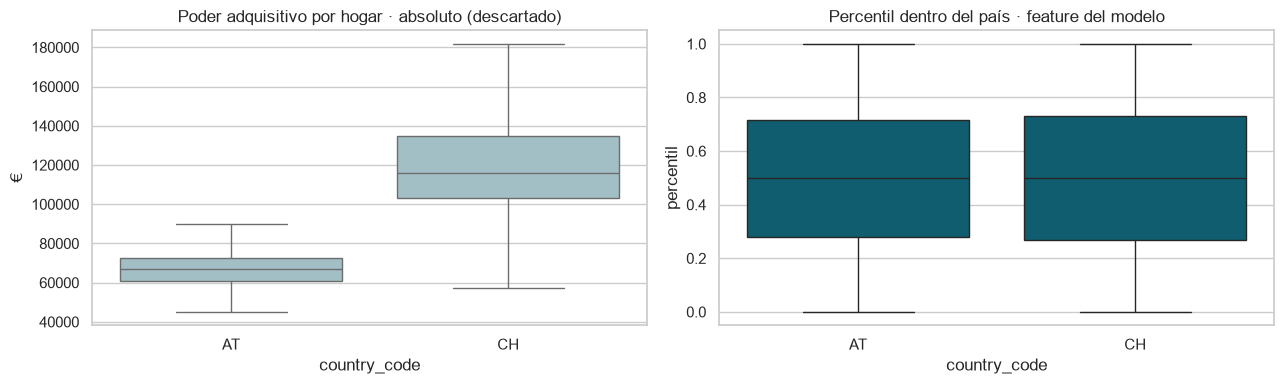

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=clientes, x="country_code", y="poder_adquisitivo_hogar_eur", showfliers=False, ax=axes[0], color="#9cc3cc")
axes[0].set(title="Poder adquisitivo por hogar · absoluto (descartado)", ylabel="€")
sns.boxplot(data=clientes, x="country_code", y="poder_adquisitivo_pct_pais", showfliers=False, ax=axes[1], color="#00677F")
axes[1].set(title="Percentil dentro del país · feature del modelo", ylabel="percentil")
plt.tight_layout()
plt.show()

In [7]:
# Comprobación: ninguna feature del modelo distingue fuertemente el país
diff = X.groupby(clientes["country_code"]).mean().T
diff["diferencia AT-CH (en desviaciones)"] = diff["AT"] - diff["CH"]
diff.sort_values("diferencia AT-CH (en desviaciones)", key=abs, ascending=False)

country_code,AT,CH,diferencia AT-CH (en desviaciones)
finance_leasing_status,-0.24,0.12,-0.37
pct_electrificado,0.17,-0.09,0.26
meses_cliente,-0.14,0.07,-0.21
pct_furgoneta,0.07,-0.04,0.11
tiene_telemetria,0.06,-0.03,0.09
antiguedad_vehiculo,-0.06,0.03,-0.09
age_range,0.04,-0.02,0.07
n_vehiculos_historico,0.02,-0.01,0.03
n_vehiculos_actuales,0.02,-0.01,0.03
n_canales_consentidos,-0.01,0.01,-0.02


### Visitas al taller: diferencia de registro entre países

Con vehículos de antigüedad casi idéntica (≈ 4,4 años en AT y 4,7 en CH), el 52 % de los clientes austriacos
figura con **0 visitas en garantía**, frente al 23 % de los suizos. Una diferencia así apunta a **cómo registra
cada mercado** las visitas, no a un comportamiento distinto. Usar el valor absoluto haría que los clusters
separaran países, así que, igual que el poder adquisitivo, se expresa como **percentil dentro del país**.

In [8]:
tabla = pd.crosstab(clientes["country_code"], clientes["visitas_taller_por_vehiculo"].clip(upper=6).round(),
                    normalize="index").mul(100).round(1)
tabla.columns = [f"{int(c)}{'+' if c == 6 else ''} visitas" for c in tabla.columns]
display(tabla)
clientes.groupby("country_code")["antiguedad_vehiculo"].median().rename("antigüedad mediana del vehículo (años)")

,0 visitas,1 visitas,2 visitas,3 visitas,4 visitas,5 visitas,6+ visitas
country_code,,,,,,,
AT,52.10,20.70,13.30,5.60,3.60,1.70,3.00
CH,22.60,15.70,19.70,13.20,10.90,6.10,11.80


country_code
AT   4.00
CH   4.32
Name: antigüedad mediana del vehículo (años), dtype: float64

Las dos variables relativas al país (poder adquisitivo y visitas al taller) no distinguen países
(diferencia ≈ 0). Las diferencias que quedan son **comportamiento real de mercado**, y se mantienen:
- **Leasing** (`finance_leasing_status`): el 29 % de los clientes suizos tiene leasing activo frente al 13 %
  de los austriacos. El leasing está muy extendido en Suiza y es una palanca comercial clave (renovaciones).
- **Electrificación**: 26 % en AT frente a 16 % en CH.

En el Reto 3 se comprueba la mezcla de países de cada cluster para confirmar que ningún segmento es "un país".

## 5. Distribuciones antes y después de la transformación

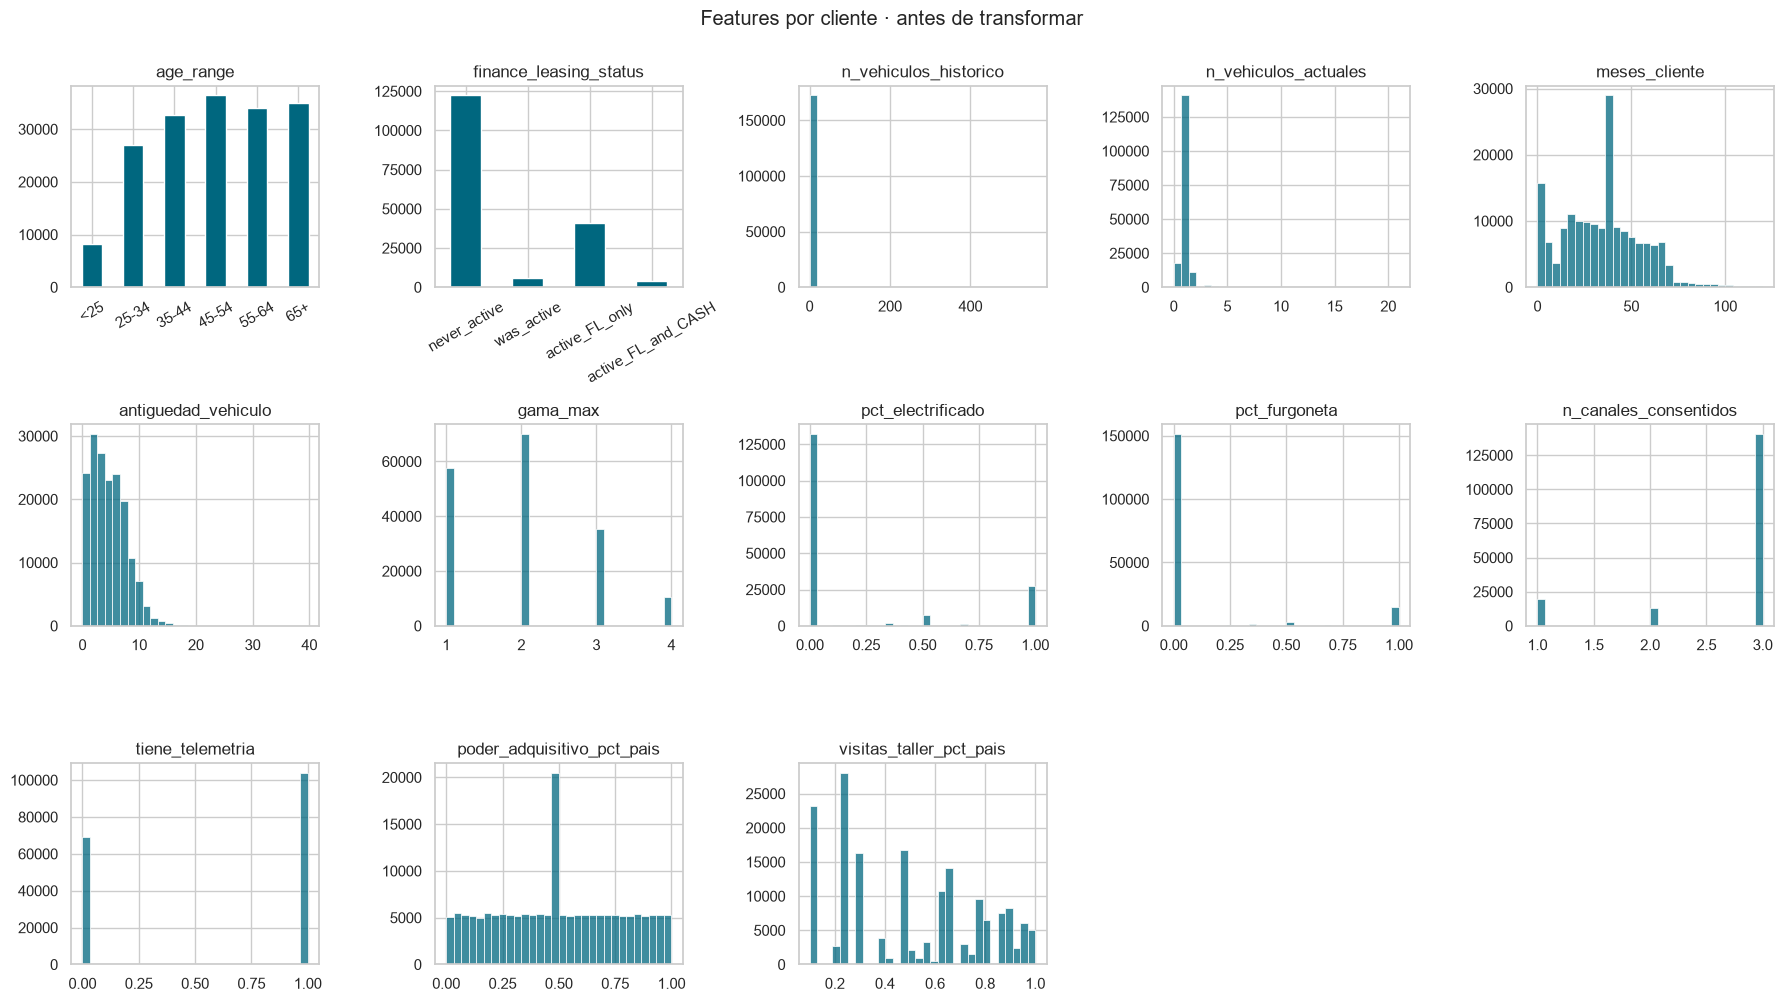

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.flat, FEATURES):
    s = clientes[col]
    if col in CAT_ORDINALES:
        orden = ORDEN_EDAD if col == "age_range" else ORDEN_FINANCIACION
        s.value_counts().reindex(orden).plot.bar(ax=ax, color="#00677F", rot=30)
    else:
        sns.histplot(s.dropna(), bins=30, ax=ax, color="#00677F")
    ax.set(title=col, xlabel="", ylabel="")
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Features por cliente · antes de transformar", y=1.0)
plt.tight_layout()
plt.show()

Dos picos visibles: `poder_adquisitivo_pct_pais` = 0,5 son los clientes sin dato socioeconómico (6 %),
imputados a la mediana de su país; y `meses_cliente` ≈ 36 concentra muchos clientes, probablemente por
una alta masiva de clientes en la plataforma conectada hace 3 años.

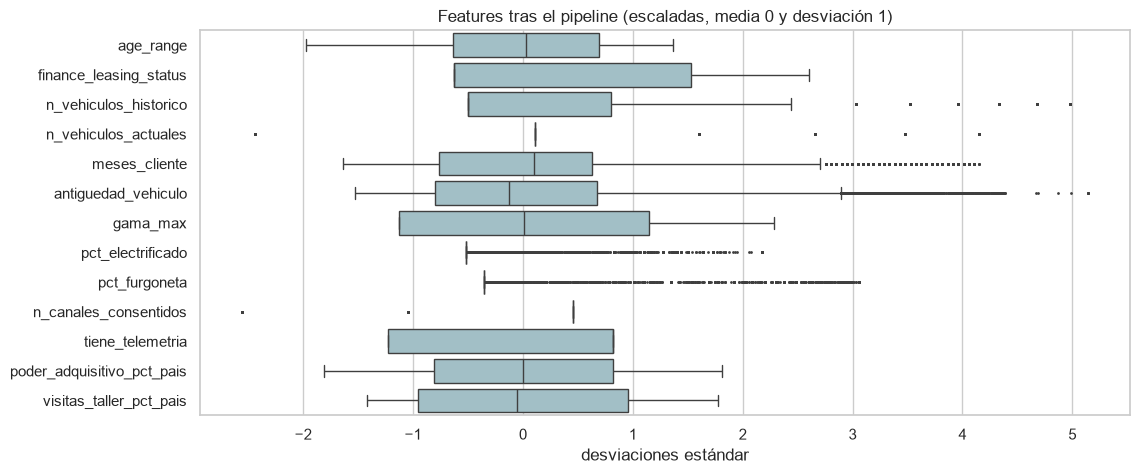

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=X, orient="h", ax=ax, color="#9cc3cc", fliersize=1)
ax.set(title="Features tras el pipeline (escaladas, media 0 y desviación 1)", xlabel="desviaciones estándar")
plt.show()

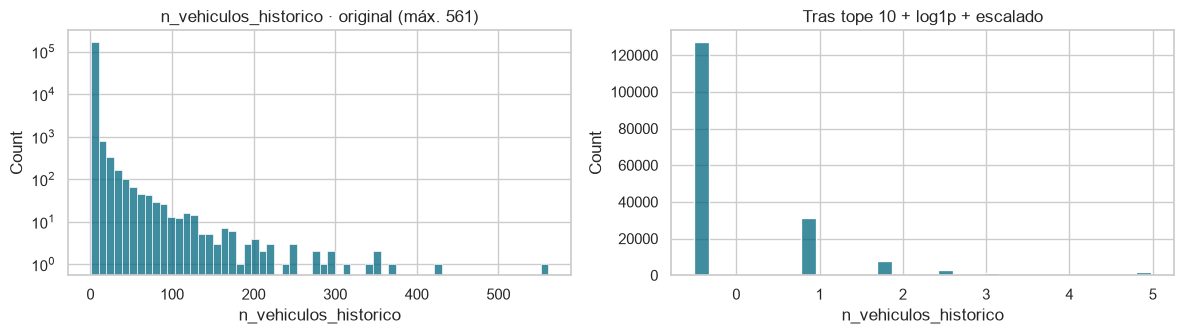

,tope superior
n_vehiculos_historico,10
n_vehiculos_actuales,5
antiguedad_vehiculo,20
meses_cliente,120


In [11]:
# Efecto del tope + log sobre el nº de vehículos (cola de flotas)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(clientes["n_vehiculos_historico"], bins=60, ax=axes[0], color="#00677F")
axes[0].set(title="n_vehiculos_historico · original (máx. 561)", yscale="log")
sns.histplot(X["n_vehiculos_historico"], bins=30, ax=axes[1], color="#00677F")
axes[1].set(title="Tras tope 10 + log1p + escalado")
plt.tight_layout()
plt.show()
pd.Series(TOPES, name="tope superior").to_frame()

## 6. Redundancia entre features

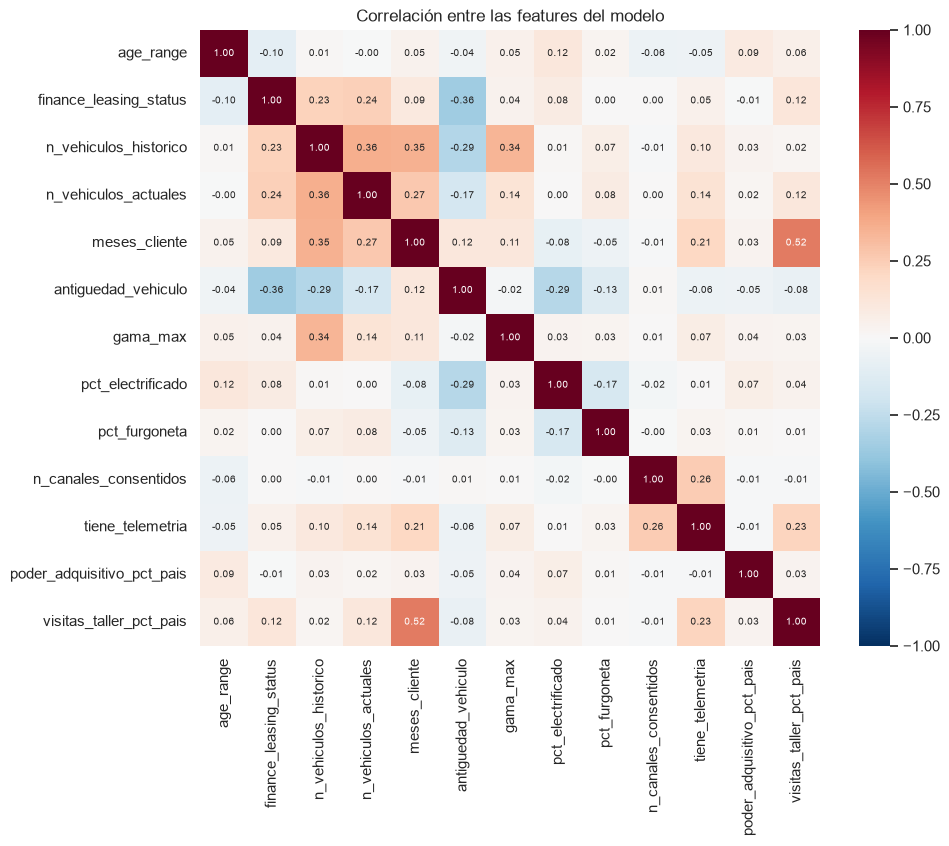

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlación entre las features del modelo")
plt.show()

Ninguna pareja de features está fuertemente correlacionada (ver la tabla). No hay features redundantes, así que cada una aporta información
distinta a K-Means.

## 7. Resultado

- **173.456 clientes × 13 features**, sin nulos, escaladas y listas para K-Means (Reto 3).
- **9 features derivadas**: antigüedad del vehículo, gama máxima, % electrificado, % furgoneta,
  nº de vehículos en el histórico, visitas al taller relativas al país, nº de canales consentidos,
  vehículo conectado y poder adquisitivo relativo al país.
- El país **no** interviene en la segmentación; se usará, junto con género, B2B, AMG y telemetría,
  para **perfilar** los segmentos en el Reto 4.
- Reutilización: `from features import cargar_datos, construir_pipeline`.

In [13]:
print("Features del modelo:", len(FEATURES))
print(" · ordinales:", CAT_ORDINALES)
print(" · log1p:", NUM_LOG)
print(" · numéricas:", NUM)
print("Columnas disponibles para perfilar:", [c for c in clientes.columns if c not in FEATURES])

Features del modelo: 13
 · ordinales: ['age_range', 'finance_leasing_status']
 · log1p: ['n_vehiculos_historico', 'n_vehiculos_actuales']
 · numéricas: ['meses_cliente', 'antiguedad_vehiculo', 'gama_max', 'pct_electrificado', 'pct_furgoneta', 'n_canales_consentidos', 'tiene_telemetria', 'poder_adquisitivo_pct_pais', 'visitas_taller_pct_pais']
Columnas disponibles para perfilar: ['country_code', 'gender_derived', 'poder_adquisitivo_hogar_eur', 'consent_phone', 'consent_email', 'consent_post', 'visitas_taller_por_vehiculo', 'pct_amg', 'es_b2b', 'trip_distance_average', 'trip_distance_median', 'operating_hours_total', 'fuel_consumption_average', 'speed_average', 'speed_median']
